# How the models work: a technical walkthrough

This notebook looks under the hood of `predictor train`. It uses the project's own code
(`predictor.trainer`) on the real datasets, so every number here is the same as what the
backend produces. It covers:

1. **Profiling**: how an arbitrary table becomes model-ready features and a JSON Schema
2. **Splitting**: train / validation / test, and why time series are split chronologically
3. **Model candidates**: baseline vs. LightGBM, and why we select on F1 / MAE
4. **Forecasting**: the horizon shift and the persistence baseline
5. **Anomaly detection**: Isolation Forest without labels
6. **ONNX export and parity**: how one graph is served without scikit-learn, and the float32 bug the parity check catches
7. **Leakage detection**

**Running it:** from `prototype/`, with the datasets generated (`python scripts/make_datasets.py`):

```bash
pip install -e ".[train,notebook]"
jupyter lab notebooks/model_internals.ipynb
```

In [1]:
import json
import os
import warnings
from collections import Counter
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import onnx
import pandas as pd
from sklearn.metrics import precision_recall_curve

from predictor.adapters.sources import read_table
from predictor.core.manifest import load_manifest
from predictor.trainer import models
from predictor.trainer.export import check_parity, make_thresholds_float32_safe, to_onnx
from predictor.trainer.profile import build_feature_schema, prepare
from predictor.trainer.run import _leakage_suspects

plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
BLUE, GREY, ORANGE, DARK = "#2563eb", "#9aa3af", "#ef6820", "#1b2230"


def load(use_case, **training_overrides):
    # Read a use case exactly like `predictor train` does: manifest -> data source -> prepare().
    manifest = load_manifest(Path("usecases") / use_case)
    training = manifest.training.model_copy(update=training_overrides)
    df = read_table(manifest.data_source.adapter, manifest.data_source.path)
    return manifest, df, prepare(df, training, manifest.policy)

## 1. Profiling: from a raw table to features

The trainer knows nothing about machines or greenhouses. `prepare()` applies the manifest
(rename, drop, policy) and then infers a **kind** for every column:

| kind | rule | encoding for the model |
|---|---|---|
| `binary` | numeric with only 0/1 (or bool) | 0.0 / 1.0 |
| `integer` | numeric, all whole numbers | float |
| `number` | other numeric | float |
| `categorical` | text with at most 50 distinct values | index in the sorted category list |

Text columns with more than 50 values (IDs, free text), constant columns and timestamps are
dropped. Everything ends up as one **float matrix**, which is what makes every model and the
ONNX runtime interchangeable. Here is the real AI4I 2020 machine data:

In [2]:
manifest, raw, data = load("machine-failure")
print(f"raw table: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head(3)

raw table: 10,000 rows x 14 columns


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0


In [3]:
print("task:", data.task, "| classes:", data.classes)
display(pd.DataFrame([{"feature": f.name, "kind": f.kind, "categories": f.categories} for f in data.features]))
data.X.head(3)  # product_quality H/L/M has become 0/1/2

task: classification | classes: ['0', '1']


,feature,kind,categories
0,product_quality,categorical,"[H, L, M]"
1,air_temp_k,number,None
2,process_temp_k,number,None
3,rotational_speed_rpm,integer,None
4,torque_nm,number,None
5,tool_wear_min,integer,None


,product_quality,air_temp_k,process_temp_k,rotational_speed_rpm,torque_nm,tool_wear_min
0,2.0,298.1,308.6,1551.0,42.8,0.0
1,1.0,298.2,308.7,1408.0,46.3,3.0
2,1.0,298.1,308.5,1498.0,49.4,5.0


The detected types are written down as a **JSON Schema** (Draft 2020-12) next to the model.
At serving time the core validates every request against exactly this schema, so training and
serving can never disagree about what a valid input is. The `x-` keys are our extensions:
column order, kind, unit and the range seen in training (used for out-of-range warnings).

In [4]:
split = models.make_split(len(data.X), manifest.training.test_fraction, data.chronological, data.y)
schema = build_feature_schema(manifest.use_case_id, data.features, data.X.iloc[split.train], manifest.training.units)
print(json.dumps({name: schema["properties"][name] for name in ["product_quality", "torque_nm"]},
                 indent=2, ensure_ascii=False))
print("x-feature-order:", schema["x-feature-order"])

{
  "product_quality": {
    "type": "string",
    "enum": [
      "H",
      "L",
      "M"
    ],
    "x-kind": "categorical"
  },
  "torque_nm": {
    "type": "number",
    "x-kind": "number",
    "x-observed-range": [
      4.6,
      76.2
    ],
    "x-unit": "Nm"
  }
}
x-feature-order: ['product_quality', 'air_temp_k', 'process_temp_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min']


## 2. Splitting: train, validation, test

Every use case is split three ways:

- **train** (~64%): the models learn from this;
- **validation** (~16%): used *only* to choose between the candidates;
- **test** (20%): touched once, at the end, for the reported metrics.

Because the winner is chosen on validation, the test score is an honest estimate for unseen data.
For classification the split is **stratified**, so the 3.4% failures appear equally in every part.

For time series the split is **chronological**: train on the past, test on the future.
A random split would put a 10:00 reading in the test set while 09:50 and 10:10 are in training,
so the model is graded on something it has practically seen already.

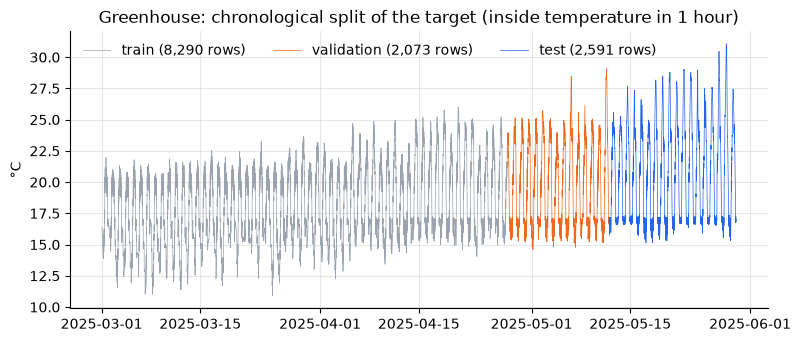

In [5]:
gh_manifest, _, gh = load("greenhouse-climate")
chrono = models.make_split(len(gh.X), 0.2, chronological=True, stratify=None)

fig, ax = plt.subplots()
for name, idx, color in [("train", chrono.train, GREY), ("validation", chrono.val, ORANGE), ("test", chrono.test, BLUE)]:
    ax.plot(gh.times.iloc[idx], gh.y.iloc[idx], color=color, lw=0.5, label=f"{name} ({len(idx):,} rows)")
ax.set(title="Greenhouse: chronological split of the target (inside temperature in 1 hour)", ylabel="°C")
ax.legend(loc="upper left", ncol=3, frameon=False);

How much does a random split flatter the model? We train the same LightGBM pipeline with both
strategies. (The two test sets are different rows, so this is an indication, not a precise
comparison.)

In [6]:
def lightgbm_test_mae(split):
    pipe = models.candidates("regression")["lightgbm"]
    pipe.fit(gh.X.iloc[split.train].to_numpy("float32"), gh.y.iloc[split.train])
    return models.evaluate("regression", pipe, gh.X.iloc[split.test], gh.y.iloc[split.test])["mae"]

shuffled = models.make_split(len(gh.X), 0.2, chronological=False, stratify=None)
pd.Series({"random split": lightgbm_test_mae(shuffled), "chronological split (used)": lightgbm_test_mae(chrono)},
          name="test MAE (°C)").round(3).to_frame()

,test MAE (°C)
random split,0.421
chronological split (used),0.762


## 3. Model candidates: a baseline against LightGBM

Each task gets two candidates (`models.candidates()`), each a scikit-learn `Pipeline` so the
preprocessing travels with the model:

- **Baseline:** median imputation → standardisation → linear or logistic regression.
  Simple, fast, and easy to explain. Any more complex model has to beat it.
- **LightGBM:** median imputation → gradient-boosted decision trees (400 trees, learning rate
  0.05, 31 leaves). Trees need no scaling and capture non-linear effects and interactions,
  such as "high torque *and* worn tool".

The hyperparameters are fixed defaults. Tuning (e.g. FLAML) could be added in the trainer
without touching the serving core.

In [7]:
X_train, X_val, X_test = (data.X.iloc[i] for i in (split.train, split.val, split.test))
y_train, y_val, y_test = (data.y.iloc[i] for i in (split.train, split.val, split.test))

fitted, rows = {}, []
for name, pipe in models.candidates("classification").items():
    pipe.fit(X_train.to_numpy("float32"), y_train)
    fitted[name] = pipe
    for part, X, y in [("validation", X_val, y_val), ("test", X_test, y_test)]:
        rows.append({"model": name, "split": part, **models.evaluate("classification", pipe, X, y)})

print(fitted["logistic_regression"])
pd.DataFrame(rows).set_index(["model", "split"]).round(3)

Pipeline(steps=[('impute',
                 SimpleImputer(keep_empty_features=True, strategy='median')),
                ('scale', StandardScaler()),
                ('model', LogisticRegression(max_iter=2000))])


accuracy     f1  roc_auc
model               split                               
logistic_regression validation     0.970  0.314    0.888
                    test           0.968  0.220    0.901
lightgbm            validation     0.986  0.747    0.981
                    test           0.985  0.741    0.970

**Why F1 and not accuracy?** Only 3.4% of the records are failures. A "model" that always
answers *no failure* already scores about 97% accuracy and never catches anything.
F1 combines **precision** (how many alarms are real) and **recall** (how many failures we
catch), so it only goes up if the rare class is predicted well.

accuracy of always predicting 'no failure': 96.6%


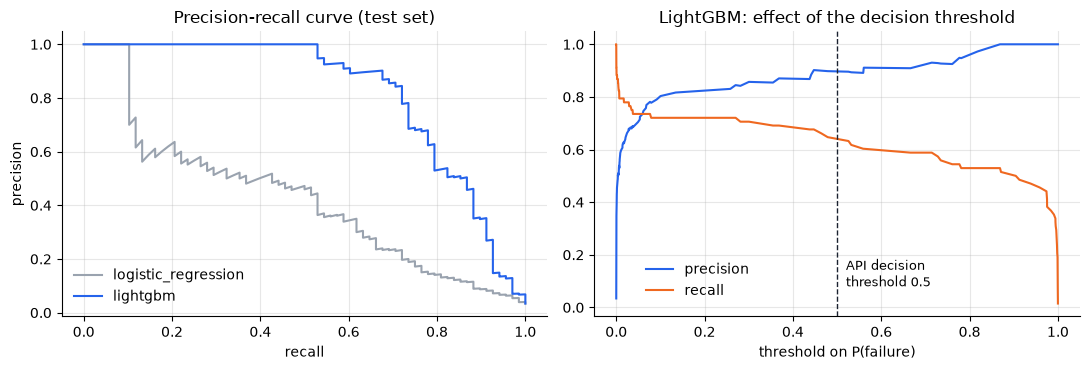

In [8]:
print(f"accuracy of always predicting 'no failure': {1 - y_test.mean():.1%}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for name, color in [("logistic_regression", GREY), ("lightgbm", BLUE)]:
    proba = fitted[name].predict_proba(X_test.to_numpy("float32"))[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_test, proba)
    ax1.plot(recall, precision, color=color, label=name)
    if name == "lightgbm":
        ax2.plot(thresholds, precision[:-1], color=BLUE, label="precision")
        ax2.plot(thresholds, recall[:-1], color=ORANGE, label="recall")
ax1.set(title="Precision-recall curve (test set)", xlabel="recall", ylabel="precision")
ax1.legend(frameon=False)
ax2.axvline(0.5, color=DARK, ls="--", lw=1)
ax2.text(0.52, 0.08, "API decision\nthreshold 0.5", fontsize=9)
ax2.set(title="LightGBM: effect of the decision threshold", xlabel="threshold on P(failure)")
ax2.legend(frameon=False, loc="lower left", bbox_to_anchor=(0.08, 0.02))
plt.tight_layout()

The API returns the class **and** the probabilities, so a client that would rather catch more
failures at the cost of more false alarms can use a lower threshold on `probabilities["1"]`
without retraining.

## 4. Forecasting: horizon shift and the persistence baseline

The greenhouse manifest says `"horizon_steps": 6` (6 × 10 minutes = 1 hour). The trainer
**shifts the target** six rows up: each row's features (the climate *now*) are paired with
the temperature *one hour later*. The current temperature stays an input.

A forecast has an obvious naive competitor: **persistence**, "in an hour it will be what it is
now". The model has to beat that, not just the linear baseline.

In [9]:
Xg = {part: gh.X.iloc[idx] for part, idx in [("train", chrono.train), ("test", chrono.test)]}
yg = {part: gh.y.iloc[idx] for part, idx in [("train", chrono.train), ("test", chrono.test)]}
forecasters = {name: pipe.fit(Xg["train"].to_numpy("float32"), yg["train"])
               for name, pipe in models.candidates("regression").items()}
persistence = gh.persistence.iloc[chrono.test]

scores = {name: models.evaluate("regression", pipe, Xg["test"], yg["test"]) for name, pipe in forecasters.items()}
scores["persistence (naive)"] = {"mae": float((persistence - yg["test"]).abs().mean())}
pd.DataFrame(scores).T.round(3)

,mae,rmse,r2
linear_regression,1.077,1.355,0.887
lightgbm,0.762,1.169,0.916
persistence (naive),1.040,NaN,NaN


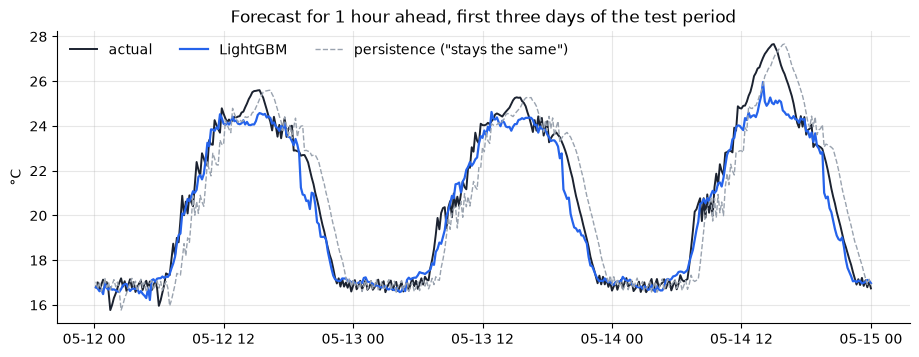

In [10]:
window = slice(0, 3 * 144)  # three days of 10-minute readings
times = gh.times.iloc[chrono.test].iloc[window]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(times, yg["test"].iloc[window], color=DARK, lw=1.4, label="actual")
ax.plot(times, forecasters["lightgbm"].predict(Xg["test"].to_numpy("float32"))[window], color=BLUE, lw=1.6, label="LightGBM")
ax.plot(times, persistence.iloc[window], color=GREY, lw=1, ls="--", label='persistence ("stays the same")')
ax.set(title="Forecast for 1 hour ahead, first three days of the test period", ylabel="°C")
ax.legend(frameon=False, ncol=3);

Persistence always lags one hour behind, which is clearly visible on every rising and falling
flank. LightGBM uses the sun, the heating and the time of day to anticipate those flanks.
It also shows a limitation of trees: LightGBM **underestimates the hottest peaks**. A tree can only
predict values it has seen in training, and the test period (mid May) is warmer than the training
period (March and April). This is why the API warns when an input is outside the training range,
and why retraining as the seasons change matters.

Which inputs matter most (share of the total split gain in the trees):

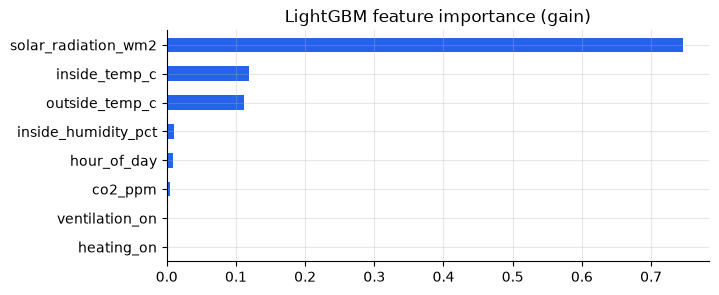

In [11]:
importance = pd.Series(models.feature_importance(forecasters["lightgbm"], list(Xg["train"].columns)))
importance.sort_values().plot.barh(color=BLUE, figsize=(7, 3), title="LightGBM feature importance (gain)");

## 5. Anomaly detection without labels: Isolation Forest

Often there are no labelled failures yet. An **Isolation Forest** builds random trees that
split on random features at random values. Unusual records are **isolated in fewer splits**
(they sit alone at the edges of the data), so their average path length is short.

`decision_function` turns that into a score: **lower = more unusual**. The manifest's
`anomaly_share: 0.05` (scikit-learn's `contamination`) puts the threshold at 0 so that 5% of the
training data falls below it. The `machine_failure` label is **not** used in training.
We only use it afterwards to check whether the flagged records are real failures.

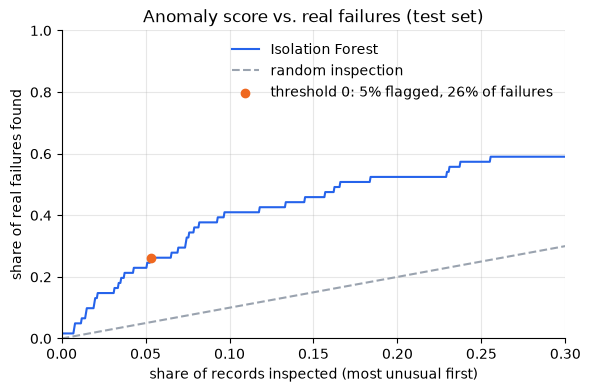

In [12]:
an_manifest, _, an = load("machine-anomaly")
an_split = models.make_split(len(an.X), 0.2, chronological=False, stratify=None)
forest = models.candidates("anomaly", an_manifest.training.anomaly_share)["isolation_forest"]
forest.fit(an.X.iloc[an_split.train].to_numpy("float32"))

scores = forest.decision_function(an.X.iloc[an_split.test].to_numpy("float32"))
failed = models._truthy(an.evaluation_label.iloc[an_split.test])

# Inspect the k most unusual records: what share of all real failures is among them?
order = np.argsort(scores)
share_flagged = np.arange(1, len(order) + 1) / len(order)
share_caught = np.cumsum(failed[order]) / failed.sum()

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(share_flagged, share_caught, color=BLUE, label="Isolation Forest")
ax.plot([0, 1], [0, 1], color=GREY, ls="--", label="random inspection")
at = np.searchsorted(share_flagged, (scores < 0).mean())
ax.scatter([share_flagged[at]], [share_caught[at]], color=ORANGE, zorder=3,
           label=f"threshold 0: {share_flagged[at]:.0%} flagged, {share_caught[at]:.0%} of failures")
ax.set(xlim=(0, 0.3), ylim=(0, 1), xlabel="share of records inspected (most unusual first)",
       ylabel="share of real failures found", title="Anomaly score vs. real failures (test set)")
ax.legend(frameon=False, loc="upper right");

The model finds several times more failures than random spot checks, without ever seeing a
label. It is still clearly weaker than the supervised classifier from section 3, which is the
expected trade-off: use anomaly detection to get started, and switch to classification once
labelled failures have been collected.

## 6. ONNX export and the parity check

The serving image contains **no scikit-learn or LightGBM**. After training, the whole fitted
pipeline (imputer → scaler → model) is converted into **one ONNX graph** with a single input
`features` (float32, shape `[n, n_features]`). The core only needs `onnxruntime` to run it,
and any future model technology just needs its own runner adapter.

In [13]:
artifact = to_onnx(fitted["lightgbm"], X_train.shape[1], "classification")
graph = onnx.load_model_from_string(artifact).graph
print(f"model.onnx: {len(artifact) / 1024:.0f} KB")
print("inputs: ", [(i.name, [d.dim_value or "n" for d in i.type.tensor_type.shape.dim]) for i in graph.input])
print("outputs:", [o.name for o in graph.output])
print("operators:", dict(Counter(node.op_type for node in graph.node)))

model.onnx: 896 KB
inputs:  [('features', ['n', 6])]
outputs: ['label', 'probabilities']
operators: {'Imputer': 1, 'TreeEnsembleClassifier': 1, 'Identity': 2}


**Parity check.** Before a model is published, `check_parity()` runs the ONNX file through the
*real* serving runner (`OnnxRunner`) and compares it to the original pipeline on the test set.
Training fails if they differ by more than 1e-4 or if any class label changes.

This check caught a real bug. LightGBM stores split thresholds as **float64**, while ONNX tree
ensembles compare in **float32**, rounding each threshold to the *nearest* float32. That rounding
can land just *above* the original threshold `t`. An input exactly on that float32 value then goes
left in ONNX and right in LightGBM. On ordinary test rows this is rare. Here is the original
pipeline, before the fix, on the normal test set:

In [14]:
cases = {
    "machine-failure (classification)": (fitted["lightgbm"], X_test, {"task_type": "classification", "classes": data.classes}),
    "greenhouse-climate (regression)": (forecasters["lightgbm"], Xg["test"], {"task_type": "regression"}),
}

def parity_table(inputs):
    rows = {}
    for name, (pipe, _, descriptor) in cases.items():
        X = inputs[name]
        rows[name] = check_parity(pipe, to_onnx(pipe, X.shape[1], descriptor["task_type"]), X, descriptor)
    return pd.DataFrame(rows).T[["rows_compared", "max_abs_diff", "label_agreement", "passed"]]

test_sets = {name: X for name, (_, X, _) in cases.items()}
parity_table(test_sets)

,rows_compared,max_abs_diff,label_agreement,passed
machine-failure (classification),2000,0.0,1.0,True
greenhouse-climate (regression),2591,0.00001,None,True


That looks fine, but sensors report rounded values, and a value sitting exactly on a split point
is entirely realistic. So we probe the boundary: take 2,000 test rows and move one feature in each
onto a split threshold of the model, as float32 represents it.

In [15]:
def boundary_probes(pipe, X, n=2000, seed=0):
    splits = []
    def walk(node):
        if "split_feature" in node:
            splits.append((node["split_feature"], node["threshold"]))
            walk(node["left_child"]), walk(node["right_child"])
    for tree in pipe.named_steps["model"].booster_.dump_model()["tree_info"]:
        walk(tree["tree_structure"])
    rng = np.random.default_rng(seed)
    probes = X.iloc[rng.integers(0, len(X), n)].reset_index(drop=True)
    for row, i in enumerate(rng.integers(0, len(splits), n)):
        feature, threshold = splits[i]
        probes.iat[row, feature] = float(np.float32(threshold))
    return probes

probes = {name: boundary_probes(pipe, X) for name, (pipe, X, _) in cases.items()}
parity_table(probes)

,rows_compared,max_abs_diff,label_agreement,passed
machine-failure (classification),2000,0.846598,0.9965,False
greenhouse-climate (regression),2000,0.523735,None,False


Here the two runtimes clearly disagree. Some machines even get a different *class*. Without the
check, the API would silently serve a different model from the one that was evaluated.

The fix, `make_thresholds_float32_safe()`, rewrites every threshold `t` to the largest float32
`f ≤ t`. For a float32 input `x`, `x ≤ t` is exactly the same test as `x ≤ f`, so LightGBM's own
predictions **do not change** for the inputs the API sends (always float32). ONNX now makes
exactly the same decisions:

In [16]:
before = {name: pipe.predict(probes[name].to_numpy("float32")) for name, (pipe, _, _) in cases.items()}
for pipe, _, _ in cases.values():
    make_thresholds_float32_safe(pipe)
for name, (pipe, _, _) in cases.items():
    change = np.abs(before[name] - pipe.predict(probes[name].to_numpy("float32"))).max()
    print(f"{name}: LightGBM's own predictions changed by snapping: {change}")

parity_table(probes)

machine-failure (classification): LightGBM's own predictions changed by snapping: 0
greenhouse-climate (regression): LightGBM's own predictions changed by snapping: 0.0


,rows_compared,max_abs_diff,label_agreement,passed
machine-failure (classification),2000,0.0,1.0,True
greenhouse-climate (regression),2000,0.000012,None,True


## 7. Leakage detection

**Target leakage** means an input that is only known *because* of the outcome. It gives perfect
test scores and a useless model in production. AI4I contains five failure-mode columns
(`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) that are recorded *after* the machine failed. The manifest
drops them. Here is what the trainer's leakage check says if we forget to:

In [17]:
_, _, leaky = load("machine-failure", drop_columns=["UDI", "Product ID"])
leaky_split = models.make_split(len(leaky.X), 0.2, False, leaky.y)
suspects = _leakage_suspects(leaky, leaky.X.iloc[leaky_split.train], leaky.y.iloc[leaky_split.train], None)
print("flagged as probable leakage:", suspects)
pd.crosstab(leaky.X["HDF"], leaky.y, rownames=["HDF (heat dissipation failure)"], colnames=["machine_failure"])

flagged as probable leakage: ['TWF', 'HDF', 'PWF', 'OSF']


machine_failure,0,1
HDF (heat dissipation failure),,
0.0,9661,224
1.0,0,115


The rule (`_leakage_suspects` in `trainer/run.py`) is deliberately simple. A binary feature is
suspicious if, whenever it is 1, the target is always the rare class. A numeric feature is
suspicious if it correlates ≥ 0.99 with a regression target. `RNF` (random failures) is not
flagged because it often occurs *without* a recorded machine failure. The warning ends up in
the training report. A human decides, because only someone who knows the domain knows when a
column becomes available.

## Summary

| Step | Where in the code | Key idea |
|---|---|---|
| Profiling + schema | `trainer/profile.py` | every table becomes a float matrix + JSON Schema shared by training and serving |
| Splitting | `trainer/models.py::make_split` | stratified for classes, chronological for time series |
| Candidates + selection | `trainer/models.py` | baseline vs. LightGBM, picked on validation (MAE / F1), reported on test |
| Forecasting | `profile.prepare` (`horizon_steps`) | shift the target, beat persistence |
| Anomaly detection | `IsolationForest` | no labels needed; threshold from `anomaly_share` |
| Export | `trainer/export.py` | one ONNX graph, float32-safe thresholds, parity checked through the real runner |
| Leakage | `trainer/run.py::_leakage_suspects` | warn when one feature (almost) determines the target |